# Notebook 03: Giai đoạn 2 — Veil + Retinex/LIME thích nghi + Dehaze + CLAHE (CIE LAB)
Không còn `haze_pivot = 172` cố định. Quy trình:
1. **Mô hình veil** $I=cJ+(1-c)A$: $V=(1-c)A$ được *đo* (percentile 1 % từng kênh), $c=1-V/A$ ⇒ $J=(I-V)/c$. Không có veil thì gần như không đổi.
2. **Phân tích phân bố sáng**: p5, p50, p95, dark ratio, dark channel ⇒ điểm số `s_dark`, `s_backlit`, `s_haze`.
3. **Nâng sáng Retinex/LIME**: $T=\mathrm{GF}(\mathrm{MaxFilter}(\max_c I))$, Adaptive Gamma $g=\ln t/\ln T_{35}$, gain mượt $G=T^{g-1}\le 5$ nhân cả 3 kênh (vùng đèn/bầu trời $T\approx1\Rightarrow G\approx1$), vai highlight mềm `tanh`; chính sách chỉ nâng toàn phần khi ảnh tối *phẳng* hoặc ngược sáng.
4. **Khử nhiễu vùng khuếch đại** (NLM + Guided Filter tự dẫn chống khối JPEG; chroma Guided Filter) và khử nhiễu cuối theo $\hat\sigma\times$ hệ số khuếch đại.
5. **Dehaze dark-channel** cường độ $\omega\,s_{haze}$, CLAHE nhẹ trên $L^*$, bù bão hoà theo pixel (giảm ở vùng tối và vùng vừa khử hồng).

In [1]:
import os, sys, cv2, pandas as pd
ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))  # notebook đặt trong notebooks/
sys.path.insert(0, ROOT)
from src.uav_pipeline import run_stage2_adaptive
img = cv2.imread(f"{ROOT}/data/real_uav/esp32_real_052.jpg")
s2, l_in, l_out, info = run_stage2_adaptive(img)
info

p5,p50,p95,dark_ratio,bright_ratio,dc_mean,s_dark,s_backlit,s_haze,w_dark_flat,veil,veil_c,p5_post,p50_post,p95_post,dark_ratio_post,bright_ratio_post,dc_mean_post,s_dark_post,s_backlit_post,s_haze_post,lift_policy,gamma,illum_p35,gain_mean,post_lift_sigma,black_anchor_shift,sigma_eff,noise_amp,c_gain
44.0,44.0,84.0,0.001,0.0,0.161,1.0,0.0,0.0,1.0,0.062,0.903,30.0,31.0,75.0,0.748,0.0,0.114,1.0,0.0,0.0,1.0,0.45,0.13,2.693,0.0,0.093,2.693,2.693,1.229


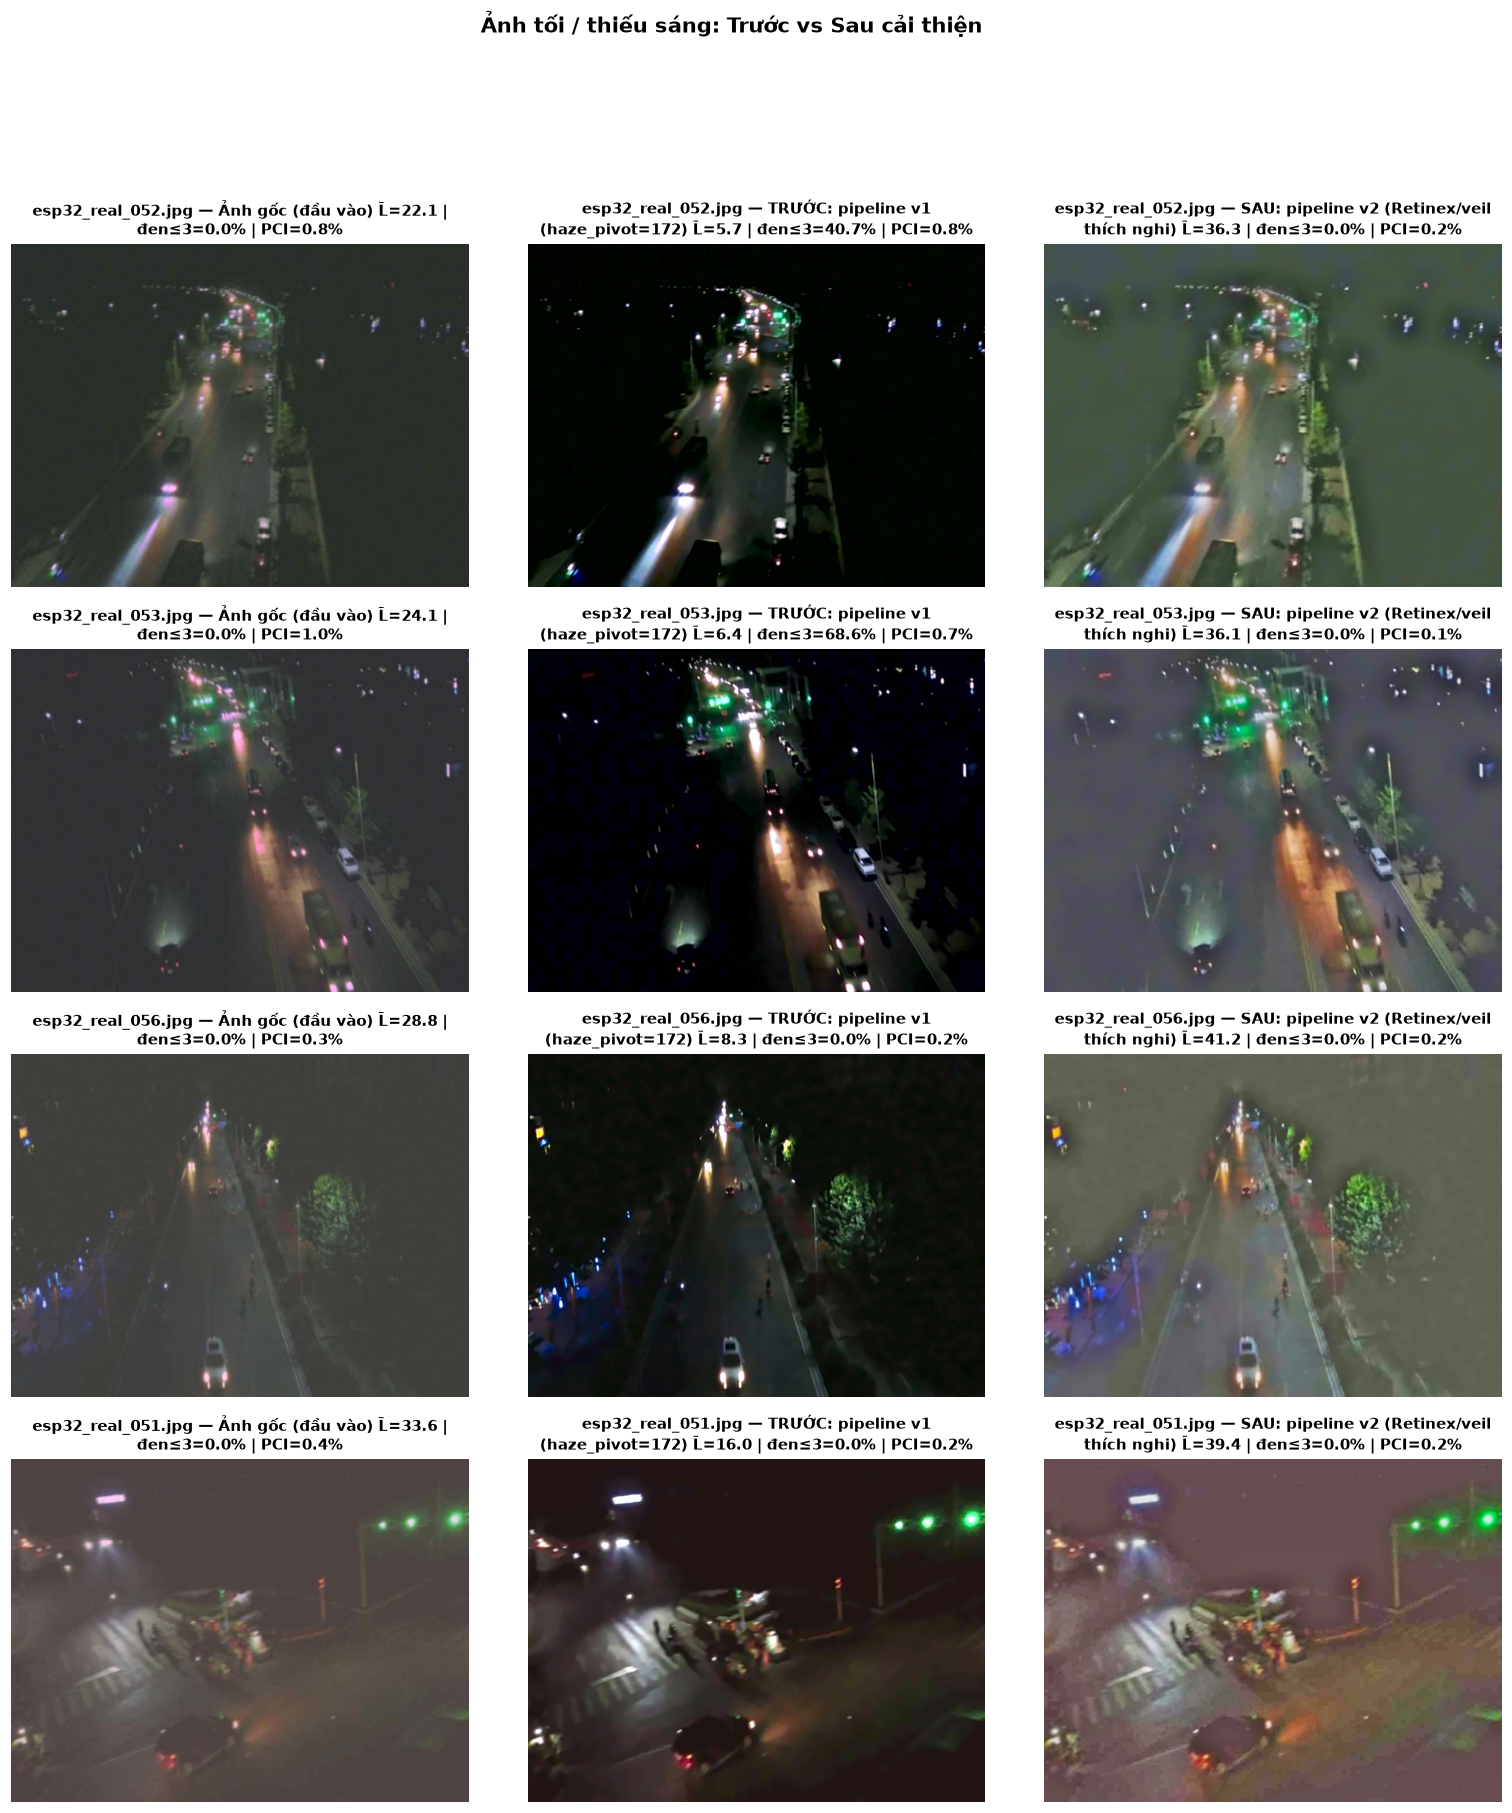

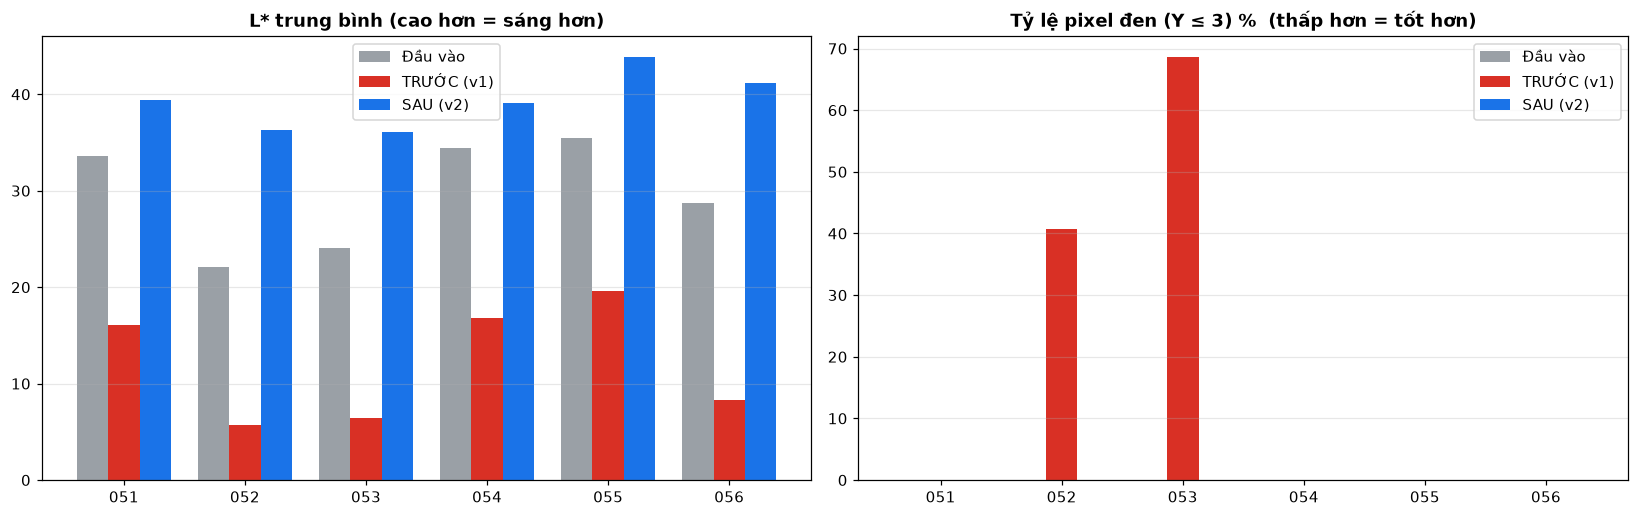

In [2]:
# Ảnh tối: Trước vs Sau

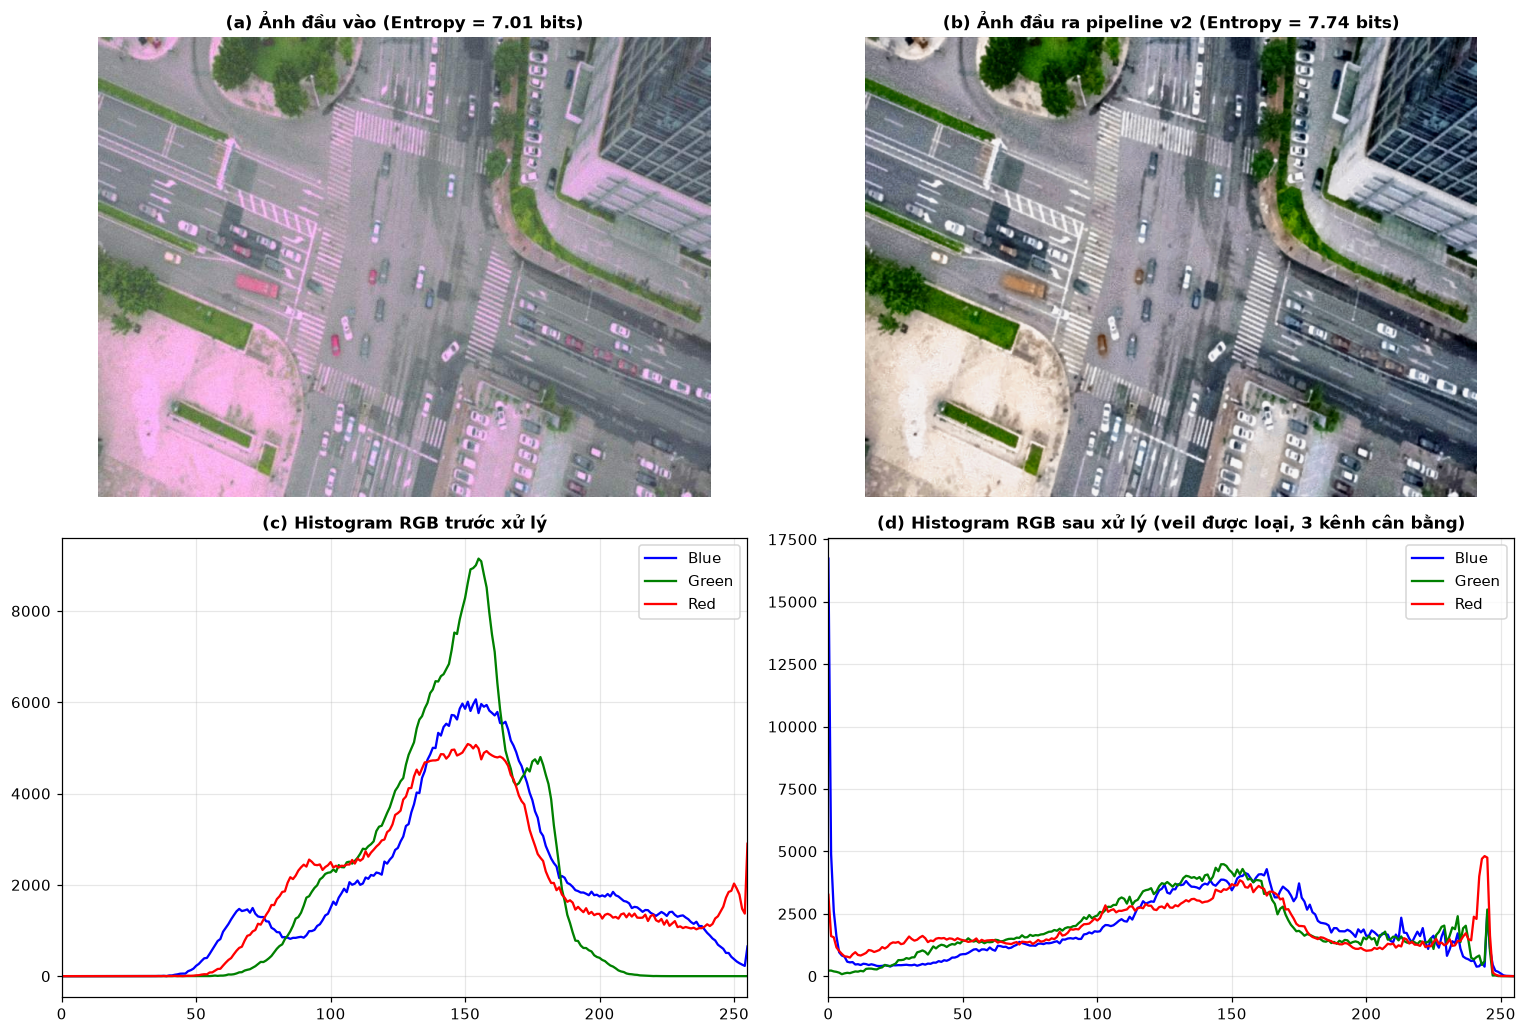

In [3]:
# Histogram RGB